# 3. Cuadrado con un pozo: ¿hace falta el sumidero $W_-$ en el transporte?

**Nomenclatura:** la del Cap. I de la tesis (`docR.tex`, `ChaptersR/CapI_ADR.tex`, rama `reestructura-4caps`).
Las referencias «ec. (nombre)» remiten a sus etiquetas `\label{eq:nombre}`. La tabla de símbolos está en §0.

**Pregunta.** El modelo ADR~(transporte_adr) incluye el sumidero de soluto
$W_-=\chi(Q)\,g_\varepsilon\,C_m$ (ec. W_menos, hipótesis M8). La tesis deja abierta la decisión F7–F8:
(a) mantenerlo, (b) usar la forma conservativa o (c) suprimirlo en la forma no conservativa. En el código está
anulado desde el 28-oct-2026 (`factor_sumidero_C = 0`). Aquí se revisa a fondo:

1. **Teoría (§1–2):** la cancelación de la Sección «Transporte del contaminante» y lo que implica para $W_-$.
2. **Modelo mínimo (§3–7):** cuadrado de 600 m con un pozo central, volúmenes finitos escritos aquí, tres
   formulaciones del transporte con *el mismo* flujo. Cuatro experimentos: $C_m$ uniforme, limpieza, pluma y barrido
   en $Q$ y $\mathbf D$. En todos se mide **cómo y cuánto contaminante se escapa por el pozo** con y sin $W_-$.
3. **Simulador (§8):** las corridas reales: BFR en el cuadrado (grupo Z) y FEniCS en el dominio real (grupo S).

### Veredicto (detalle en §9): apoya la opción (c), o la (b), que es equivalente

| | sin $W_-$ (forma no conservativa) | con $W_-$ |
|---|---|---|
| ¿sale el contaminante por el pozo? | **sí**, por $-\mathbf u\cdot\nabla C_m$: la forma no conservativa ya contiene la extracción | sí, *la misma* masa total |
| $C_m$ uniforme ($C_m\equiv C_0$, solución exacta) | se conserva exactamente | agujero en el pozo |
| concentración en el pozo $c_g$ (la que entra en $J_m$) | correcta | 2× menor ($\kappa=Q$) o ~100–300× menor (ec. W_menos) |
| con poco bombeo y mucha dispersión | extrae $\approx Q\,C_m$ | **extrae contaminante que el pozo no puede sacar** (sumidero fantasma) |

**$W_-$ no hace falta en la forma no conservativa, y con él el modelo es incorrecto.**

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
import rutas
from cuadrado_nucleo import Cuadrado, DIA
import simulador as S

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
COL = {"cons": "k", "nc": "tab:blue", "Wq": "tab:orange", "W1": "tab:red", "fd": "tab:cyan", "fd1": "tab:pink"}
NOM = {"cons": "conservativa (referencia)", "nc": "no conservativa sin $W_-$", "Wq": "no cons. + $W_-$, $\\kappa=Q$",
       "W1": "no cons. + $W_-$ de la ec. W_menos ($\\kappa=1$)", "fd": "no cons. (FD) sin $W_-$",
       "fd1": "no cons. (FD) + $W_-$ ($\\kappa=1$)"}
TXT = {k: v.replace("$", "").replace("\\kappa", "κ").replace("W_-", "W₋") for k, v in NOM.items()}  # para tablas de texto
CORTO = {"nc": "sin $W_-$", "W1": "con $W_-$ ($\\kappa=1$)"}
FORMAS = {"cons": ("cons", 0, None), "nc": ("nc_fv", 0, None), "Wq": ("nc_fv", 1, None),
          "W1": ("nc_fv", 1, 1.0), "fd": ("nc_fd", 0, None), "fd1": ("nc_fd", 1, 1.0)}

## 0. Símbolos (Cap. I de la tesis)

| símbolo | significado | en el código |
|---|---|---|
| $\Omega$, $Q_T=\Omega\times(0,T)$ | dominio y cilindro espacio-tiempo | |
| $h$ | carga hidráulica | `H` |
| $\mathbf K$, $S_s$, $\phi$, $R$, $\lambda_d$ | conductividad, almacenamiento específico, porosidad, retardo, decaimiento | `K`, `S_s`, `pho`/`phi`, `R`, `landa` |
| $\mathbf u=-\mathbf K\nabla h$ | velocidad de Darcy (ec. darcy), **no** la de poro | `U`, `V`, `u` |
| $C_m$ | concentración del contaminante (región móvil) | `C` |
| $\mathbf D(\mathbf x,\mathbf u)$ | tensor de dispersión hidrodinámica (ec. dispersion_diag) | `D` |
| $\mathbf x_p=(x_p,z_p)$ | posición del pozo | `pozo` |
| $Q(t)$ | tasa de bombeo por unidad de anchura (m²/s) | `Qout`, `Q_std` |
| $w_R$, $R_w$ | núcleo de Wendland del sumidero de flujo (ec. kernel_wendland) y su radio | `delta_p`, `r_pozo` |
| $g_\varepsilon$, $\varepsilon=R_w/3$ | núcleo gaussiano del sumidero de soluto y de $J_m$ (ec. kernel_gp) | `gauss_p`, `delta_C`, `epsilon_pozo` |
| $f=-Q\,w_R$ | sumidero de la ecuación de flujo (ec. pozo_fuente) | `QOut*delta` |
| $W=W_+-W_-$ | fuente y sumidero de soluto (ec. W_mas, ec. W_menos) | |
| $\chi(Q)=\tfrac12(1+\tanh(Q/\varepsilon_\chi))$ | compuerta suave del bombeo, $\varepsilon_\chi=10^{-6}$ | `chi_eps` |
| $J_m=\int_0^T\!\int_\Omega g_\varepsilon C_m^2$ | calidad del agua extraída (Cap. III, ec. Jm) | |

Símbolos propios de este notebook:

| símbolo | significado |
|---|---|
| $f_W$ | `factor_sumidero_C`: multiplica a $W_-$ (0 = anulado, 1 = la ec. W_menos) |
| $\kappa$ | intensidad de un sumidero $\kappa\,g_\varepsilon C_m$: $\kappa=1$ es la ec. W_menos ($\chi\approx1$), $\kappa=Q$ es su versión con el caudal |
| $c_g(t)=\int_\Omega g_\varepsilon C_m\,d\Omega$ | concentración en el entorno del pozo (la que pesa $J_m$; el simulador la llama «C captada») |
| $c_w(t)=\int_\Omega w_R\,C_m\,d\Omega$ | concentración del agua extraída: la masa sale del acuífero a razón $Q\,c_w$ |
| $m(t)=\int_\Omega\phi R\,C_m\,d\Omega$ | masa de soluto en el dominio |

## 1. $W_-$ en el código

Los dos backends resuelven la ec. (transporte_adr):
$$
\phi R\,\frac{\partial C_m}{\partial t}+\lambda_d\,\phi R\,C_m=\nabla\cdot(\mathbf D\nabla C_m)-\mathbf u\cdot\nabla C_m+W_+-f_W\,W_- ,
\qquad W_-=\chi(Q)\,g_\varepsilon\,C_m ,
$$
acoplada con el flujo (ec. flujo) $S_s\,\partial_t h-\nabla\cdot(\mathbf K\nabla h)=-Q\,w_R$. El pozo **sí** está en
el flujo.

| dónde | qué hace |
|---|---|
| `fenicsx/forward.py:353` | `+ f_W * theta_C * inner(delta_C * C, z_t) * dx`, con `delta_C` $=\chi(Q)\,g_\varepsilon$ (`:575`) |
| `funtions/operators.py:475` | `coef_identity -= w * sig * p.factor_sumidero_C * gauss_p` |
| `preprocessing/preprocess.py:73` | `gauss_p = gaussian_2d(nodes, pozo, 1, epsilon_pozo)`: $g_\varepsilon$ con $\int g_\varepsilon=1$ |
| `funtions/utils.py:165` | `chi_eps`: $\chi(Q)$ con $\varepsilon_\chi=10^{-6}$ |

**El sumidero no lleva el caudal.** $\chi(Q)\,g_\varepsilon$ tiene dimensiones de m$^{-2}$ y no de s$^{-1}$. La
tesis ya lo anota tras la ec. (W_menos): equivale a fijar en 1 m²/s una tasa de extracción que no se modela, **sea
cual sea $Q$**. Con $Q_{std}=0.3$ eso es 3.3 veces el caudal real; con el $Q=0.01$ del cuadrado, 100 veces; y con
$Q=10^{-5}$ (pozo casi apagado, $\chi\approx1$) el sumidero sigue entero. En BFR la compuerta es aún más gruesa:
se activa si la lista `Qout` no está vacía. Abajo se escribe el sumidero en general como $\kappa\,g_\varepsilon C_m$
y se prueban $\kappa=Q$ (la versión con el caudal) y $\kappa=1$ (la ec. W_menos).

## 2. Teoría: la extracción ya está en la forma no conservativa

Es el argumento del párrafo «Forma conservativa y forma no conservativa» del Cap. I. Aquí se repite para sacar
consecuencias que se puedan comprobar.

**Forma conservativa** (ec. transporte_conservativo). El agua bombeada sale con la concentración residente:
$$
\frac{\partial}{\partial t}(\phi R\,C_m)+\nabla\cdot\bigl(\mathbf u\,C_m-\mathbf D\nabla C_m\bigr)+\lambda_d\,\phi R\,C_m
=W_+-Q\,w_R\,C_m .
$$
**Divergencia de la velocidad** (ec. div_u con $f=-Q\,w_R$): $\ \nabla\cdot\mathbf u=-Q\,w_R-S_s\,\partial_t h$.

**Paso a la forma no conservativa.** Con $\phi R$ independiente del tiempo y
$\nabla\cdot(\mathbf uC_m)=\mathbf u\cdot\nabla C_m+C_m\nabla\cdot\mathbf u$, el término
$C_m\nabla\cdot\mathbf u$ contiene exactamente $-Q\,w_R\,C_m$ y cancela el sumidero del lado derecho:
$$
\boxed{\ \phi R\,\frac{\partial C_m}{\partial t}+\lambda_d\,\phi R\,C_m
=\nabla\cdot(\mathbf D\nabla C_m)-\mathbf u\cdot\nabla C_m+W_++S_s\,\frac{\partial h}{\partial t}\,C_m\ }
\qquad\text{(ec. transporte\_noconservativo)}
$$
En la forma no conservativa el pozo actúa a través de $\mathbf u$: las líneas de corriente convergen al pozo, donde
$\nabla\cdot\mathbf u<0$, y el soluto que llega se va con el agua. **No hace falta ningún sumidero de soluto.**

**Consecuencias que se pueden comprobar** (con flujo estacionario, donde $S_s\partial_th=0$):

1. **$C_m$ uniforme.** Si $C_m\equiv C_0$ y el agua que entra por el borde trae $C_0$, las dos formas dan
   $C_m\equiv C_0$ para todo $t$: el pozo saca $QC_0$ y entra lo mismo. Con $W_-$ queda
   $\phi R\,\partial_tC_m=-\kappa g_\varepsilon C_m\ne0$, es decir, un **agujero** en el pozo. Es la prueba más limpia.
2. **Forma no conservativa + $W_-$ = forma conservativa con un sumidero de más.** Sumar $\kappa g_\varepsilon C_m$
   equivale a resolver la ec. (transporte_conservativo) con $-(Q\,w_R+\kappa\,g_\varepsilon)\,C_m$. Con $\kappa=Q$ la
   extracción se cuenta **dos veces**.
3. **La masa total que sale casi no cambia.** Fuera del entorno del pozo ($r\gtrsim R_w$) las dos ecuaciones son
   idénticas, así que la masa que *llega* a ese entorno por advección es la misma ($\approx Q\,C_m$ aguas arriba), y
   con o sin $W_-$ desaparece. Lo único que cambia es $C_m$ **dentro** del entorno. Con una celda bien mezclada que
   recibe $Q\,C_{in}$: $c_w=C_{in}\,Q/(Q+\kappa)$, que es $\tfrac12$ con $\kappa=Q$ y $\approx Q$ con $\kappa=1$.
4. **Lo que sí cambia es lo que mide el funcional.** $J_m$ pesa $C_m$ con $g_\varepsilon$ en el entorno del pozo. Con
   $W_-$, $c_g$ es artificialmente baja, y también su derivada respecto a $Q$ y $z_p$.
5. **Excepción:** si la dispersión alimenta el agujero ($\mathbf D$ grande, $Q$ pequeño), $W_-$ con $\kappa=1$ saca
   masa que el pozo no podría extraer. Se mide en §7.

**¿De dónde salió $W_-$?** En los peldaños 2a (Parte B) y 2c (`benchmarks_libro/libro`) el pozo es un sumidero
$u_i\psi_i\,y$ en la ecuación de transporte, **porque allí la velocidad es la de Graetz y no siente el pozo**
($\nabla\cdot\mathbf b=0$). En ese problema es correcto. En el acuífero, en cambio, el pozo cambia el flujo
($\nabla\cdot\mathbf u=-Q\,w_R$) y la extracción ya está dentro de $-\mathbf u\cdot\nabla C_m$, así que ponerla
además la cuenta dos veces.

**El término de almacenamiento.** La ec. (transporte_noconservativo) lleva $+S_s(\partial_th)\,C_m$ **porque allí
se fijó $\phi$ constante** en la forma conservativa. Pero con almacenamiento el contenido de agua no es constante:
$\partial_t\theta=S_s\,\partial_th$. Con $\theta(t)=\phi+S_s(h-h_0)$ en la acumulación,
$\partial_t(\theta C_m)=\theta\,\partial_tC_m+C_m S_s\partial_th$ y el término se **cancela otra vez**:
$\theta\,\partial_tC_m+\mathbf u\cdot\nabla C_m=\nabla\cdot(\mathbf D\nabla C_m)$ es la forma no conservativa
coherente, **sin** $S_s\partial_th\,C_m$. Por tanto la ec. (transporte_adr) no «omite» nada que haga falta: lo que
sobra es el $+S_s\partial_th\,C_m$ de la ec. (transporte_noconservativo) si se usa con $\theta$ variable, y lo que
produce masa aparente es medirla como $\phi\int C_m$ con $S_s$ grande. Se comprueba en el Experimento E (§7.1).
Un campo uniforme $C_m\equiv C_0$ debe seguir uniforme sea cual sea el flujo, y sólo lo cumplen las formas con
$\theta(t)$ o con $S_s$ despreciable.

## 3. Modelo mínimo: cuadrado con pozo central (volúmenes finitos)

$\Omega=(-300,300)^2$ m, celdas de $\approx10$ m ($61\times61$), pozo en $\mathbf x_p=(0,0)$ con los núcleos del
simulador: $w_R$ con $R_w=20$ m (flujo) y $g_\varepsilon$ con $\varepsilon=R_w/3$ ($W_-$ y $c_g$).
$\mathbf K=10^{-3}\,\mathbf I$, $\phi=0.1$, $R=1$, $\lambda_d=0$, $W_+=0$, $Q=0.01$ (como el grupo Z) y
$\mathbf D=D\,\mathbf I$ con $D=10^{-5}$ salvo en §7.

**Flujo:** estacionario, con $h=300$ en el borde (lo que produce la condición «libre» en el cuadrado, ver grupo Z) y
continuidad discreta exacta: la salida neta de la celda $i$ es $-Q\,w_{R,i}$, el análogo discreto de la ec. (div_u).

**Transporte:** Euler implícito, $\Delta t=0.25$ d, upwind. Tres discretizaciones con el mismo flujo:

| clave | ecuación | discretización |
|---|---|---|
| `cons` | ec. (transporte_conservativo) | VF con caudales de cara: la **referencia física** (conserva masa por construcción) |
| `nc` | ec. (transporte_noconservativo) $-\,f_W\kappa g_\varepsilon C_m$ | VF de la forma conservativa menos $C_{m,i}\times$(continuidad discreta): $\sum_{f\,\text{entrante}}F_f(C_{m,vec}-C_{m,i})$ |
| `fd` | ec. (transporte_noconservativo) $-\,f_W\kappa g_\varepsilon C_m$ | diferencias por nodo con $\mathbf u$ en el nodo, **sin** caudales de cara (como RBF-FD y FEM en el simulador) |

`nc` con $f_W=0$ es *algebraicamente* igual a `cons`. `fd` comprueba que la conclusión no depende de esa identidad
discreta.

continuidad discreta: max|Σ_f F_f + Q w_R,i|/Q = 1.1e-13


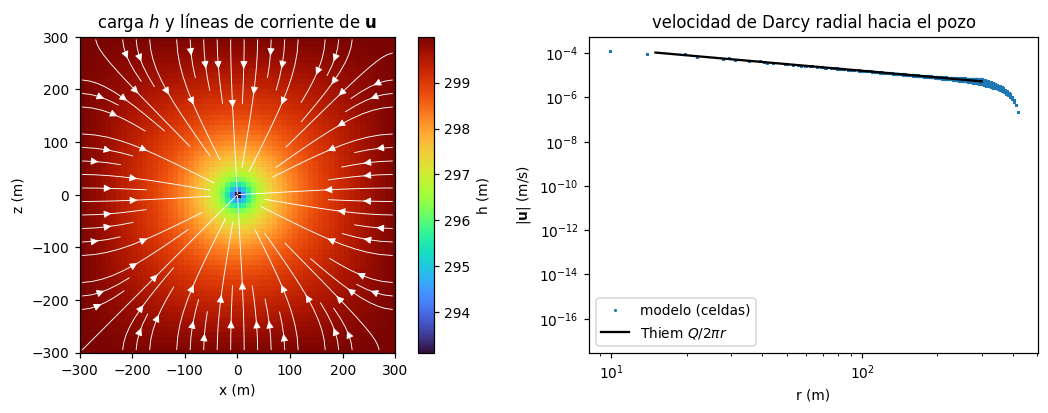

In [2]:
m = Cuadrado()
print(f"continuidad discreta: max|Σ_f F_f + Q w_R,i|/Q = {m.err_continuidad:.1e}")
r = np.hypot(m.X, m.Z).ravel()
u_mod = np.hypot(m.ux, m.uz)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
im = ax[0].imshow(m.h.reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), cmap="turbo")
ax[0].streamplot(m.X[:, 0], m.Z[0], m.ux.reshape(m.n, m.n).T, m.uz.reshape(m.n, m.n).T, color="w", density=0.8, linewidth=0.6)
plt.colorbar(im, ax=ax[0], label="h (m)"); ax[0].set_title("carga $h$ y líneas de corriente de $\\mathbf{u}$"); ax[0].set_aspect("equal")
ax[0].set(xlabel="x (m)", ylabel="z (m)")
rr = np.linspace(15, 300, 100)
ax[1].loglog(r, u_mod, ".", ms=2, label="modelo (celdas)")
ax[1].loglog(rr, m.Q / (2 * np.pi * rr), "k-", label="Thiem $Q/2\\pi r$")
ax[1].set(xlabel="r (m)", ylabel="$|\\mathbf{u}|$ (m/s)", title="velocidad de Darcy radial hacia el pozo"); ax[1].legend()
plt.tight_layout(); plt.show()

Lejos del pozo $|\mathbf u|$ sigue a Thiem, salvo en las esquinas, donde el borde cuadrado lo hace más lento.
Tiempo de viaje desde $r$: $\pi r^2\phi/Q$, unos 21 d desde $r=240$ m.

## 4. Experimento A: $C_m$ uniforme (la prueba de consistencia)

$C_m(\cdot,0)=1$ en todo el cuadrado, el agua que entra por el borde trae $C_m=1$ y $T=30$ d.
**Solución exacta:** $C_m\equiv1$.

formulación                                 m(T)/m(0)    c_w(T)    c_g(T)   min C_m
conservativa (referencia)                    1.000000         1         1  1.00e+00
no conservativa sin W₋                       1.000000         1         1  1.00e+00
no cons. + W₋, κ=Q                           0.999013    0.4656    0.5344  3.43e-01
no cons. + W₋ de la ec. W_menos (κ=1)        0.995122  0.001483  0.009985  2.21e-05
no cons. (FD) sin W₋                         1.000000         1         1  1.00e+00
no cons. (FD) + W₋ (κ=1)                     0.995142  0.001492   0.01024  1.89e-07


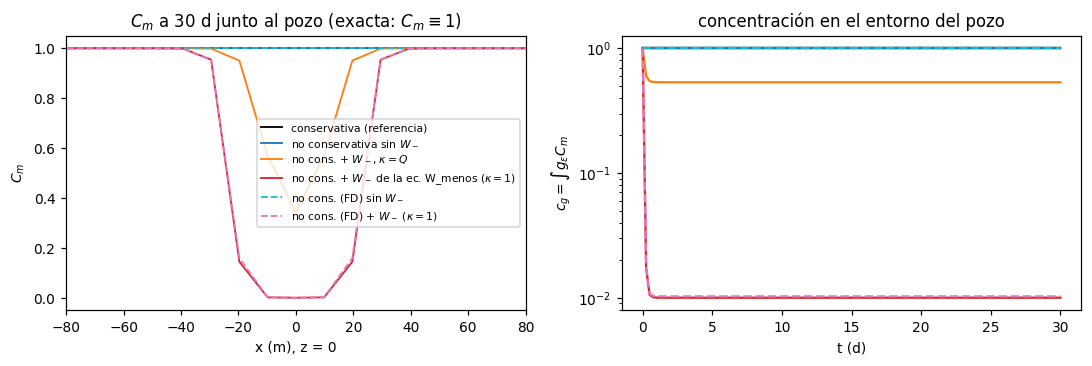

In [3]:
def correr(m, clave, C0, C_b=0.0, T=30, dt=0.25):
    forma, fW, k = FORMAS[clave]
    return m.correr(forma, C0, C_b=C_b, T_fin=T * DIA, dt=dt * DIA, f_W=fW, kappa=k)

A = {k: correr(m, k, np.ones(m.N), C_b=1.0) for k in FORMAS}
print(f"{'formulación':42s} {'m(T)/m(0)':>10s} {'c_w(T)':>9s} {'c_g(T)':>9s} {'min C_m':>9s}")
for k, o in A.items():
    print(f"{TXT[k]:42s} {o['masa'][-1] / o['masa'][0]:10.6f} {o['c_w'][-1]:9.4g} {o['c_g'][-1]:9.4g} {o['C'][-1].min():9.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
j0 = m.n // 2
x = m.X[:, 0]
for k, o in A.items():
    ax[0].plot(x, o["C"][-1].reshape(m.n, m.n)[:, j0], color=COL[k], label=NOM[k], lw=1.2,
               ls="--" if k.startswith("fd") else "-")
    ax[1].semilogy(o["t"], np.maximum(o["c_g"], 1e-6), color=COL[k], ls="--" if k.startswith("fd") else "-")
ax[0].set(xlim=(-80, 80), xlabel="x (m), z = 0", ylabel="$C_m$", title="$C_m$ a 30 d junto al pozo (exacta: $C_m\\equiv1$)")
ax[1].set(xlabel="t (d)", ylabel="$c_g=\\int g_\\varepsilon C_m$", title="concentración en el entorno del pozo")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Sin $W_-$ el $C_m$ uniforme se conserva a precisión de máquina** en las tres discretizaciones, incluida `fd`, que
no usa la continuidad discreta. **Con $W_-$ aparece un agujero** que no corresponde a nada físico: con $\kappa=Q$ el
pozo ve la mitad ($Q/(Q+\kappa)=\tfrac12$, consecuencia 3) y con la ec. (W_menos) ($\kappa=1$) ve $\approx10^{-3}$.
La masa $m$ apenas cambia (0.1–0.5 %) porque el agujero ocupa sólo el entorno del pozo.

## 5. Experimento B: limpieza del cuadrado (cómo se escapa el contaminante)

$C_m(\cdot,0)=1$ salvo una franja limpia de 60 m junto al borde (como el grupo Z), y el agua que entra es limpia
($C_b=0$). Con $W_+=0$ el soluto sólo puede salir por el pozo, porque por el borde sólo entra agua.

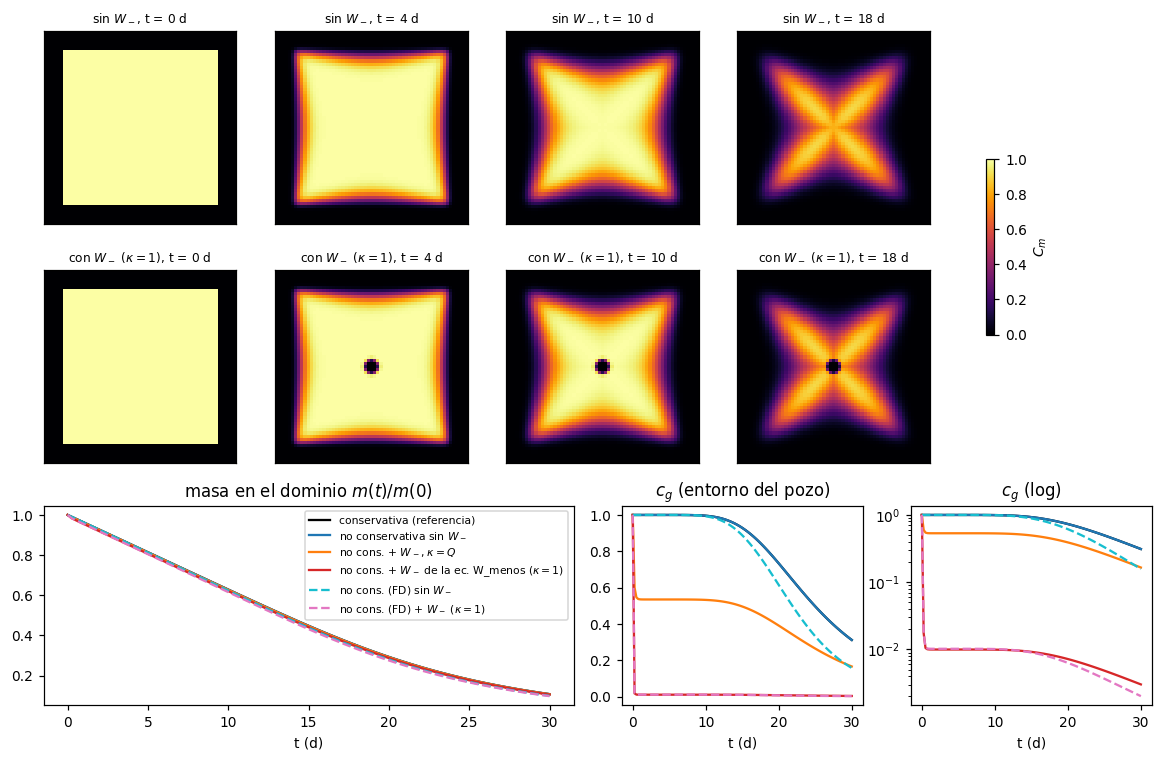

formulación                                 pérdida a 10 d   a 30 d  Q∫c_w dt / m0  + κ∫c_g dt / m0
conservativa (referencia)                           0.3718   0.8924         0.8924           0.8924
no conservativa sin W₋                              0.3718   0.8924         0.8924           0.8924
no cons. + W₋, κ=Q                                  0.3733   0.8929         0.4153           0.8929
no cons. + W₋ de la ec. W_menos (κ=1)               0.3793   0.8948         0.0013           0.8948
no cons. (FD) sin W₋                                0.3769   0.9009         0.8229           0.8229
no cons. (FD) + W₋ (κ=1)                            0.3844   0.9024         0.0012           0.8531


In [4]:
limpio = ((np.abs(m.X) < 240) & (np.abs(m.Z) < 240)).ravel() * 1.0
B = {k: correr(m, k, limpio, T=30) for k in ("cons", "nc", "Wq", "W1", "fd", "fd1")}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1])
dias = (0, 4, 10, 18)
for fila, k in enumerate(("nc", "W1")):
    o = B[k]
    for c, d in enumerate(dias):
        a = fig.add_subplot(gs[fila, c])
        it = int(round(d / 0.25))
        im = a.imshow(o["C"][it].reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), vmin=0, vmax=1, cmap="inferno")
        a.set_title(f"{CORTO[k]}, t = {d} d", fontsize=8); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=fig.axes, shrink=0.4, location="right", label="$C_m$")
a1, a2, a3 = fig.add_subplot(gs[2, 0:2]), fig.add_subplot(gs[2, 2]), fig.add_subplot(gs[2, 3])
for k, o in B.items():
    ls = "--" if k.startswith("fd") else "-"
    a1.plot(o["t"], o["masa"] / o["masa"][0], color=COL[k], ls=ls, label=NOM[k])
    a2.plot(o["t"], o["c_g"], color=COL[k], ls=ls)
    a3.semilogy(o["t"], np.maximum(o["c_g"], 1e-5), color=COL[k], ls=ls)
a1.set(xlabel="t (d)", title="masa en el dominio $m(t)/m(0)$"); a1.legend(fontsize=7)
a2.set(xlabel="t (d)", title="$c_g$ (entorno del pozo)"); a3.set(xlabel="t (d)", title="$c_g$ (log)")
plt.show()

print(f"{'formulación':42s} {'pérdida a 10 d':>15s} {'a 30 d':>8s} {'Q∫c_w dt / m0':>14s} {'+ κ∫c_g dt / m0':>16s}")
for k, o in B.items():
    m0 = o["masa"][0]
    k_ = FORMAS[k][2]
    kap = 0.0 if FORMAS[k][1] == 0 else (m.Q if k_ is None else k_)
    sale = m.Q * np.sum(o["c_w"][1:]) * o["dt"] / m0
    sale_W = kap * np.sum(o["c_g"][1:]) * o["dt"] / m0
    print(f"{TXT[k]:42s} {1 - o['masa'][40] / m0:15.4f} {1 - o['masa'][-1] / m0:8.4f} {sale:14.4f} {sale + sale_W:16.4f}")

**Cómo se escapa el contaminante.** En la fila de arriba (sin $W_-$), el frente limpio avanza desde el borde hacia el
pozo y el soluto se va por el pozo. En la de abajo (con la ec. W_menos) pasa **lo mismo**: $m(t)$ baja con la misma
curva (diferencia < 1 % de $m(0)$). La única diferencia visible es el punto negro del centro, el agujero.

La tabla cierra el balance. En `cons` y `nc` lo que sale por el pozo, $Q\int c_w\,dt$, es exactamente la masa
perdida. Con $W_-$ la masa se va por dos vías a la vez, $Q\,c_w+\kappa\,c_g$, que suman lo mismo que antes. Por eso,
con $W_-$, quien calcule la masa extraída como $Q\,c_w$ la **subestima** 2× ($\kappa=Q$) o entre $10^2$ y $10^3$ veces
($\kappa=1$). `fd` no conserva masa exactamente: su $Q\int c_w$ cierra al ~91 %, aunque la curva de masa sea la
misma. Pasa lo mismo con RBF-FD y FEM, que discretizan la forma no conservativa; se ve en §8.

## 6. Experimento C: una pluma que llega al pozo (lo que ve el bombeo)

Pluma gaussiana ($\sigma=40$ m) centrada a 160 m del pozo, agua limpia por el borde y 30 d. La curva de llegada
(BTC) $c_g(t)$ es lo que pesa $J_m$.

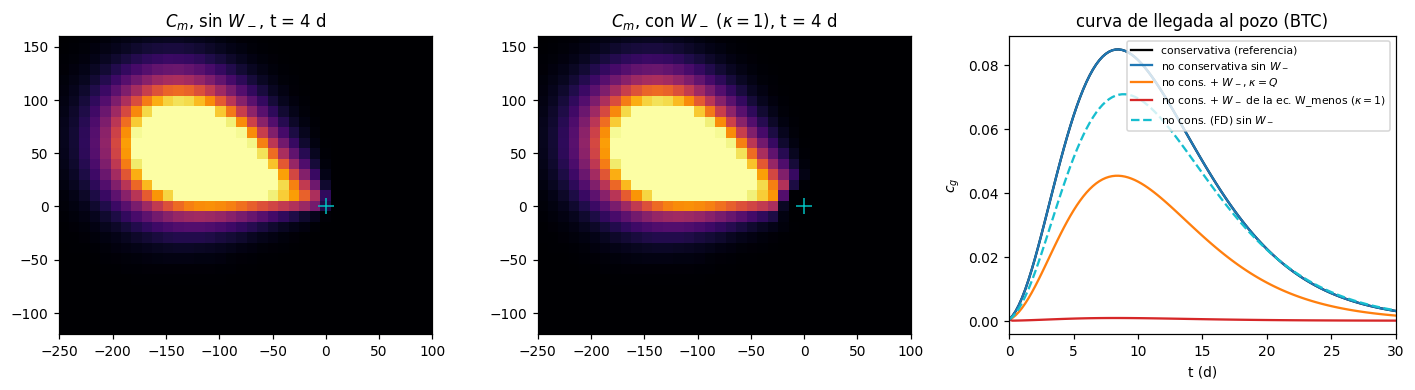

conservativa (referencia)                  pico de c_g 0.0848 en t =  8.50 d   m(30 d)/m(0) 1.16e-02
no conservativa sin W₋                     pico de c_g 0.0848 en t =  8.50 d   m(30 d)/m(0) 1.16e-02
no cons. + W₋, κ=Q                         pico de c_g 0.0453 en t =  8.50 d   m(30 d)/m(0) 1.15e-02
no cons. + W₋ de la ec. W_menos (κ=1)      pico de c_g 0.0008 en t =  8.25 d   m(30 d)/m(0) 1.11e-02
no cons. (FD) sin W₋                       pico de c_g 0.0708 en t =  9.00 d   m(30 d)/m(0) 1.07e-02


In [5]:
pluma = np.exp(-((m.X.ravel() + 150) ** 2 + (m.Z.ravel() - 60) ** 2) / (2 * 40 ** 2))
Cp = {k: correr(m, k, pluma, T=30) for k in ("cons", "nc", "Wq", "W1", "fd")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for i, (k, d) in enumerate((("nc", 4), ("W1", 4))):
    it = int(round(d / 0.25))
    ax[i].imshow(Cp[k]["C"][it].reshape(m.n, m.n).T, origin="lower", extent=(-300, 300, -300, 300), vmin=0, vmax=0.4, cmap="inferno")
    ax[i].plot(0, 0, "c+", ms=10); ax[i].set_title(f"$C_m$, {CORTO[k]}, t = {d} d"); ax[i].set_xlim(-250, 100); ax[i].set_ylim(-120, 160)
for k, o in Cp.items():
    ax[2].plot(o["t"], o["c_g"], color=COL[k], ls="--" if k == "fd" else "-", label=NOM[k])
ax[2].set(xlabel="t (d)", ylabel="$c_g$", title="curva de llegada al pozo (BTC)", xlim=(0, 30)); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
for k, o in Cp.items():
    i = o["c_g"].argmax()
    print(f"{TXT[k]:42s} pico de c_g {o['c_g'][i]:.4f} en t = {o['t'][i]:5.2f} d   m(30 d)/m(0) {o['masa'][-1] / o['masa'][0]:.2e}")

La pluma llega al pozo **en el mismo instante** con o sin $W_-$ y se extrae entera en los dos casos. El pico de
$c_g$ con $W_-$ es la mitad ($\kappa=Q$) o desaparece ($\kappa=1$). Un optimizador que minimice $J_m$ con $W_-$
activo vería una pluma de 2 a 100 veces más débil que la que de verdad sale por el pozo.

## 7. Experimento D: barrido en caudal y dispersión (el sumidero fantasma)

Limpieza de 30 d con $Q\in[10^{-4},10^{-1}]$ y $\mathbf D=D\,\mathbf I$ con dos valores de $D$. Se mide la
fracción de masa que se ha ido del dominio.

(9 s)
     D       Q |               1 - m(30 d)/m(0)               |          c_g(30 d)          
               |     cons       nc    W κ=Q    W κ=1  κ=1/cons |     cons    W κ=Q    W κ=1
 1e-05   1e-04 |   0.0112   0.0112   0.0139   0.0321      2.88 |        1    0.582 0.000152
 1e-05   1e-03 |   0.1116   0.1116   0.1133   0.1231      1.10 |        1    0.533    0.001
 1e-05   1e-02 |   0.8883   0.8883   0.8888   0.8908      1.00 |    0.321     0.17  0.00312
 1e-05   1e-01 |   1.0000   1.0000   1.0000   1.0000      1.00 | 4.01e-16 2.13e-16 3.71e-17
 1e-03   1e-04 |   0.0091   0.0091   0.0175   0.2593     28.35 |    0.678    0.644  0.00141
 1e-03   1e-03 |   0.0892   0.0892   0.1306   0.2969      3.33 |     0.64     0.45  0.00162
 1e-03   1e-02 |   0.6564   0.6564   0.6629   0.6801      1.04 |    0.293    0.151  0.00282
 1e-03   1e-01 |   1.0000   1.0000   1.0000   1.0000      1.00 | 3.56e-06 1.89e-06 3.35e-07


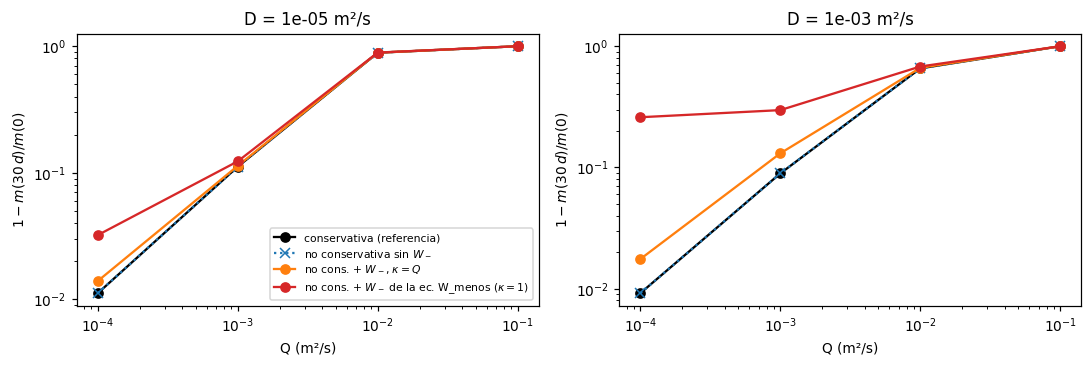

In [6]:
filas = []
t0 = time.time()
for D in (1e-5, 1e-3):
    for Qv in (1e-4, 1e-3, 1e-2, 1e-1):
        mm = Cuadrado(Q=Qv, D=D)
        lim = ((np.abs(mm.X) < 240) & (np.abs(mm.Z) < 240)).ravel() * 1.0
        res = {k: correr(mm, k, lim, T=30, dt=0.5) for k in ("cons", "nc", "Wq", "W1")}
        filas.append((D, Qv, {k: 1 - o["masa"][-1] / o["masa"][0] for k, o in res.items()},
                      {k: o["c_g"][-1] for k, o in res.items()}))
print(f"({time.time() - t0:.0f} s)")
print(f"{'D':>6s} {'Q':>7s} | {'1 - m(30 d)/m(0)':^44s} | {'c_g(30 d)':^28s}")
print(f"{'':15s}| {'cons':>8s} {'nc':>8s} {'W κ=Q':>8s} {'W κ=1':>8s} {'κ=1/cons':>9s} | {'cons':>8s} {'W κ=Q':>8s} {'W κ=1':>8s}")
for D, Qv, p, c in filas:
    print(f"{D:6.0e} {Qv:7.0e} | {p['cons']:8.4f} {p['nc']:8.4f} {p['Wq']:8.4f} {p['W1']:8.4f} {p['W1'] / p['cons']:9.2f} |"
          f" {c['cons']:8.3g} {c['Wq']:8.3g} {c['W1']:8.3g}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for i, D in enumerate((1e-5, 1e-3)):
    Qs = [f[1] for f in filas if f[0] == D]
    for k in ("cons", "nc", "Wq", "W1"):
        ax[i].loglog(Qs, [f[2][k] for f in filas if f[0] == D], "o-" if k != "nc" else "x:", color=COL[k], label=NOM[k])
    ax[i].set(xlabel="Q (m²/s)", ylabel="$1-m(30\\,d)/m(0)$", title=f"D = {D:.0e} m²/s")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 7.1 Experimento E: flujo transitorio y almacenamiento ($S_s$)

Hasta aquí el flujo era estacionario. Con $S_s\ne0$ el bombeo arranca en $t=0$ con $h\equiv h_b$ y la velocidad se
construye en el tiempo: $\sum_fF_f=-Q\,w_R-S_sA\,\partial_th$ (ec. div_u completa). `transitorio_nucleo.py` resuelve
ese flujo (Euler implícito, continuidad discreta exacta) y el transporte en cuatro formas:
`cons` y `nc` con $\phi$ constante (como los backends), y `consT`, `ncT` con $\theta(t)=\phi+S_s(h-h_b)$.
Limpieza de 30 d (como el Experimento B), sin $W_-$. Se mide el cierre del balance, masa perdida menos $Q\int c_w\,dt$
(con $\theta\!\int C_m$ en las formas T), y si $C_m\equiv1$ se conserva.

In [7]:
from transitorio_nucleo import CuadradoTransitorio
lim_ = None
print(f"{'S_s':>7s} {'forma':6s} {'perdida':>8s} {'Q∫c_w/m0':>9s} {'cierre':>8s} {'c_w(30 d)':>9s} {'C≡1: mín':>9s}")
for S_s in (1e-5, 1e-2, 0.1):
    mt = CuadradoTransitorio(S_s=S_s)
    lim_ = ((np.abs(mt.X) < 240) & (np.abs(mt.Z) < 240)).ravel() * 1.0
    M0 = mt.masa(lim_)
    for f in (("cons", "nc") if S_s != 1e-2 else ("nc", "consT", "ncT")):
        if S_s == 0.1 and f in ("consT", "ncT"):
            continue
        o = mt.correr_tr(f, lim_, T_fin=30 * DIA, dt=0.5 * DIA)
        Mfin = mt.A * (o["theta"] * o["C"]).sum() if f.endswith("T") else o["masa"][-1]
        u1 = mt.correr_tr(f, np.ones(mt.N), T_fin=30 * DIA, dt=0.5 * DIA, C_b=1.0)
        print(f"{S_s:7.0e} {f:6s} {1 - Mfin / M0:8.4f} {o['sale'][-1] / M0:9.4f} {1 - Mfin / M0 - o['sale'][-1] / M0:+8.4f} "
              f"{o['c_w'][-1]:9.3f} {u1['C'].min():9.4f}")

    S_s forma   perdida  Q∫c_w/m0   cierre c_w(30 d)  C≡1: mín


  1e-05 cons     0.8883    0.8883  +0.0000     0.319    1.0000


  1e-05 nc       0.8883    0.8884  -0.0001     0.319    1.0000


  1e-02 nc       0.8484    0.9525  -0.1040     0.413    1.0000


  1e-02 consT    0.8937    0.8937  +0.0000     0.311    1.0000


  1e-02 ncT      0.8938    0.8933  +0.0005     0.310    1.0000


  1e-01 cons     0.5705    0.5705  +0.0000     0.507    0.5340


  1e-01 nc       0.3675    1.1105  -0.7430     0.955    1.0000


* Con el $S_s$ realista del cuadrado ($10^{-5}$ m$^{-1}$) las formas **coinciden** y el almacenamiento es
  irrelevante: $\Delta\theta/\phi\sim-7\cdot10^{-4}$.
* Con $S_s=\phi=0.1$ m$^{-1}$ (el valor por defecto del simulador, `S_s = φ`; dimensionalmente $S_s$ no es
  adimensional como $\phi$) la forma `nc` con $\phi$ constante **pierde 37 % en vez de 57 %** y su «salida con el
  agua» $Q\int c_w$ llega a 111 % de $m_0$. Es la misma firma que el 149 % del grupo Z (§8.1). Además
  $\theta=\phi+S_s(h-h_b)$ llega a $-0.54$ cerca del pozo (el abatimiento es de 6.9 m): contenido de agua negativo, así que
  **ese $S_s$ no es físico**.
* Con $S_s=10^{-2}$ y $\theta(t)$ (`consT` y `ncT`) el balance cierra a $10^{-4}$ y $C_m\equiv1$ se conserva. La
  `nc` con $\phi$ constante no cierra (10 % de $m_0$; aquí $\theta$ baja hasta 0.03).
* La forma `cons` con $\phi$ constante **no** conserva un campo uniforme cuando $S_s$ es grande (mín $0.53$): es
  la inconsistencia de fijar $\phi$. La forma no conservativa sin término, la de los backends, sí lo hace.

**Conclusión del experimento.** Para $C_m$ de agua no hace falta ningún $S_s\partial_th\,C_m$. Lo que hay que
corregir es el **parámetro** $S_s=\phi$ por un valor del orden $10^{-5}$–$10^{-4}$ m$^{-1}$, o usar $\theta(t)$.
También se comprobó que $c_w$ y $c_g$ (núcleos $w_R$ y $g_\varepsilon$) difieren menos de 1 % sin $W_-$
(0.319 frente a 0.321 con $S_s=10^{-5}$), así que la elección del núcleo de $J_m$ importa mucho menos que $W_-$.

* Con dispersión pequeña y $Q\ge10^{-3}$, la masa perdida es **la misma** con y sin $W_-$ (consecuencia 3): el
  término no saca más soluto, sólo cambia $C_m$ en el entorno del pozo. Con $Q=10^{-4}$, la ec. (W_menos) ya saca
  2.9 veces más que el pozo físico.
* Con dispersión grande y poco caudal, la ec. (W_menos) **saca contaminante que el pozo no puede extraer**. Con
  $Q=10^{-4}$ el pozo físico saca ~1 % en 30 d y $W_-$, ~26 %: la dispersión rellena el agujero y $W_-$ se lo lleva.
  Para la optimización esto es grave, porque premia encender el pozo con un caudal mínimo: $\chi(Q)\approx1$ desde
  $Q\sim10\,\varepsilon_\chi=10^{-5}$.
* La forma no conservativa sin $W_-$ reproduce la referencia conservativa en todos los casos.

## 8. Lo mismo en el simulador

### 8.1 BFR en el cuadrado (grupo Z, rama `exp/sumidero-W`)

Cuadrado de 600 m, pozo central, condición libre en todo el borde, $Q=0.01$, $S_s=10^{-5}$, $\phi=0.1$, anisotropía
$\alpha=2$ ($|u_x|\approx4.8\,|u_z|$), $C_0$ salvo una franja limpia de 60 m y 90 d. Z0 sin $W_-$; Z1 con la
ec. (W_menos) ($f_W=1$).

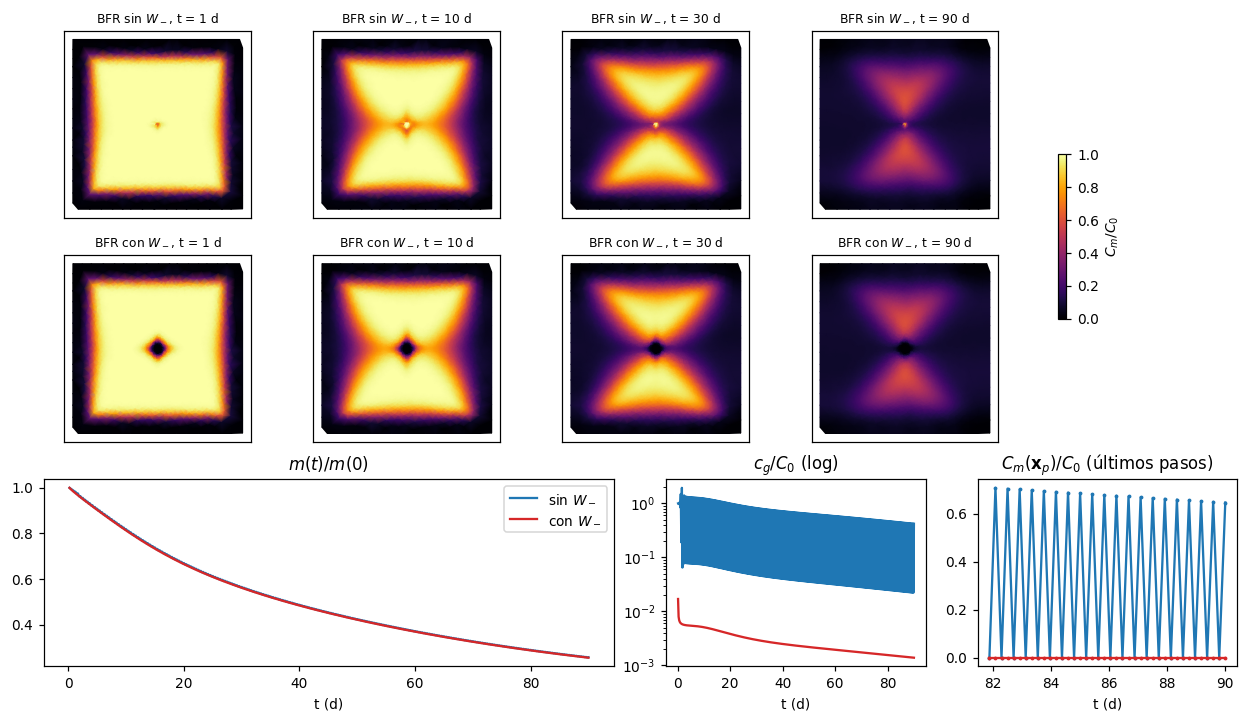

sin W-: m(t)/m(0) a 10/30/60/90 d = 0.8183, 0.5649, 0.3713, 0.2563   c_g/C0 mediana (2.ª mitad) = 0.2286
con W-: m(t)/m(0) a 10/30/60/90 d = 0.8128, 0.5612, 0.3686, 0.2543   c_g/C0 mediana (2.ª mitad) = 0.0018


In [8]:
Z = {"sin": S.cargar_Z("Z0_sin_sumidero"), "con": S.cargar_Z("Z1_con_sumidero")}
fig = plt.figure(figsize=(14, 7.5))
gs = fig.add_gridspec(3, 4)
for fila, k in enumerate(("sin", "con")):
    z = Z[k]
    for c, d in enumerate((1, 10, 30, 90)):
        a = fig.add_subplot(gs[fila, c])
        it = int(np.argmin(np.abs(z["t"] - d)))
        tp = a.tripcolor(z["tri"], z["C"][it], vmin=0, vmax=1, cmap="inferno", shading="gouraud")
        a.set_title(f"BFR {k} $W_-$, t = {z['t'][it]:.0f} d", fontsize=8); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
fig.colorbar(tp, ax=fig.axes, shrink=0.4, location="right", label="$C_m/C_0$")
a1, a2, a3 = fig.add_subplot(gs[2, 0:2]), fig.add_subplot(gs[2, 2]), fig.add_subplot(gs[2, 3])
for k, col in (("sin", "tab:blue"), ("con", "tab:red")):
    z = Z[k]
    a1.plot(z["t"], z["masa"], color=col, label=f"{k} $W_-$")
    a2.semilogy(z["t"], np.maximum(z["c_g"], 1e-5), color=col)
    a3.plot(z["t"][-40:], z["c_nodo_pozo"][-40:], ".-", color=col, ms=3)
a1.set(xlabel="t (d)", title="$m(t)/m(0)$"); a1.legend()
a2.set(xlabel="t (d)", title="$c_g/C_0$ (log)"); a3.set(xlabel="t (d)", title="$C_m(\\mathbf{x}_p)/C_0$ (últimos pasos)")
plt.show()
for k, z in Z.items():
    print(f"{k} W-: m(t)/m(0) a 10/30/60/90 d = " + ", ".join(f"{z['masa'][np.argmin(np.abs(z['t'] - d))]:.4f}" for d in (10, 30, 60, 90))
          + f"   c_g/C0 mediana (2.ª mitad) = {np.median(z['c_g'][len(z['t']) // 2:]):.4f}")

El simulador hace lo mismo que el modelo mínimo:
* **$m(t)$ baja igual con y sin $W_-$** (25.6 % y 25.4 % de $m(0)$ a 90 d): **en los dos casos el contaminante se
  escapa por el pozo**. No se limpia del todo en 90 d por la anisotropía: el pozo drena rápido en $x$ y despacio en
  $z$.
* Con $W_-$, $c_g$ cae entre 100 y 300 veces (a ≈0.001–0.005 de $C_0$), del orden de $(Q+\kappa)/Q=101$ que predice
  la celda bien mezclada.
* Sin $W_-$, $C_m(\mathbf x_p)$ alterna entre 0 y 0.65 $C_0$ de un paso a otro. **Diagnóstico verificado en
  §8.1.1**: no es el recorte $C_m\ge0$ ni el paso de tiempo. El recorte *oculta* una inestabilidad local del esquema
  centrado en el pozo que, sin recorte, crece exponencialmente. Con upwind desaparece.

### 8.1.1 ¿Qué produce la oscilación? (grupo `Zo_oscilacion`, BFR, 30 d, sin $W_-$)

Cada caso cambia **una** cosa respecto a la base (centrado, $\theta_C=1$, $\Delta t=5$ h, recorte $C\ge0$):
sin recorte (`clip_C=False`), upwind, $\Delta t/2$ y Crank–Nicolson ($\theta_C=\tfrac12$).

caso                           C(x_p)/C0, 2.ª mitad   máx |C|/C0  1.er paso |C|>10C0  m(30 d)/m0
base (centrado, recorte)   [        0,      1.68]         3.76                   —       0.565
sin recorte                [-2.13e+60,  6.69e+60]     9.95e+60        23 (r=1.9 m)     1.1e+58
upwind                     [    0.627,     0.877]            1                   —       0.568
Δt/2                       [ 7.66e+56,  4.5e+123]    6.69e+123        24 (r=1.9 m)   7.35e+120
Crank–Nicolson             [ 1.48e+39,  8.43e+87]     1.25e+88        17 (r=1.9 m)    1.38e+85


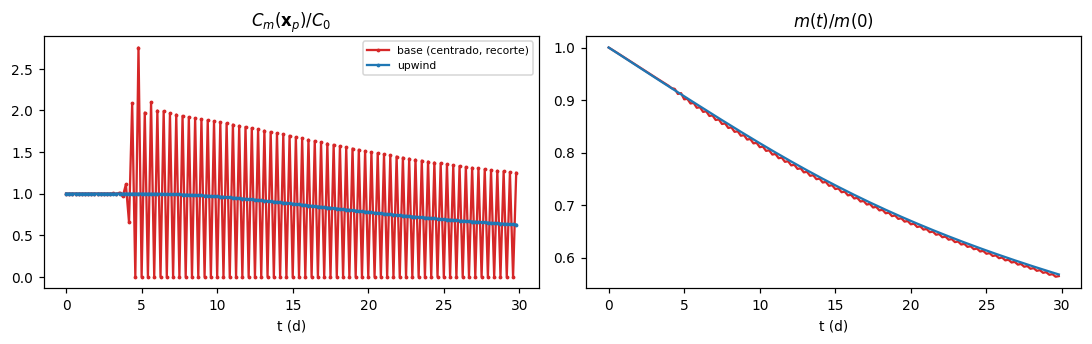

In [9]:
ZO = {k: S.cargar_Zo(k) for k in ("Zo0_base", "Zo1_sin_recorte", "Zo2_upwind", "Zo3_dt_mitad", "Zo4_cn")}
ROT = {"Zo0_base": "base (centrado, recorte)", "Zo1_sin_recorte": "sin recorte", "Zo2_upwind": "upwind",
       "Zo3_dt_mitad": "Δt/2", "Zo4_cn": "Crank–Nicolson"}
print(f"{'caso':26s} {'C(x_p)/C0, 2.ª mitad':>24s} {'máx |C|/C0':>12s} {'1.er paso |C|>10C0':>19s} {'m(30 d)/m0':>11s}")
for k, z in ZO.items():
    m2 = len(z["t"]) // 2
    ex = np.nonzero(z["max_abs"] > 10)[0]
    print(f"{ROT[k]:26s} [{z['c_nodo_pozo'][m2:].min():9.3g}, {z['c_nodo_pozo'][m2:].max():9.3g}] {z['max_abs'].max():12.3g} "
          f"{(str(ex[0]) + ' (r=' + format(z['r_max'][ex[0]], '.1f') + ' m)') if len(ex) else '—':>19s} {z['masa'][-1]:11.3g}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for k, col in (("Zo0_base", "tab:red"), ("Zo2_upwind", "tab:blue")):
    ax[0].plot(ZO[k]["t"], ZO[k]["c_nodo_pozo"], ".-", ms=3, color=col, label=ROT[k])
    ax[1].plot(ZO[k]["t"], ZO[k]["masa"], color=col)
ax[0].set(xlabel="t (d)", title="$C_m(\\mathbf{x}_p)/C_0$"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="t (d)", title="$m(t)/m(0)$")
plt.tight_layout(); plt.show()

* **Con esquema centrado la solución explota (~$10^{60}$ o más) salvo que el recorte la contenga.** Sin recorte
  explota la base; $\Delta t/2$ y Crank–Nicolson explotan **aunque el recorte esté puesto**, porque el recorte sólo
  elimina valores negativos y no frena el crecimiento positivo. Con $\Delta t=5$ h el modo alterna de signo en cada
  paso, y el recorte lo trunca en cero: de ahí la alternancia. El modo
  inestable nace en el nodo del pozo ($r<2$ m) al cabo de 17–23 pasos y crece exponencialmente. **El recorte lo
  convierte en la alternancia 0 ↔ 1.4 $C_0$ que se veía: es el resto truncado de un modo que crece.**
* Con **upwind** el nodo del pozo es suave (0.63–0.88 $C_0$), el máximo de $C_m$ es 1.002 $C_0$ (principio del
  máximo) y la masa coincide con la base a 0.3 % (0.568 frente a 0.565). El centrado, en cambio, produce
  sobreoscilaciones de hasta 3.8 $C_0$ en el pozo.
* Es una propiedad del **operador espacial**: no depende del recorte, de $\Delta t$ ni del esquema temporal. La
  hipótesis anterior (recorte + centrado) queda **refutada en su primera mitad** y confirmada en la segunda.
* Consecuencia: **toda corrida BFR sin upwind con el pozo activo** (grupos A–D, S, Z y la configuración estándar)
  tiene un modo local creciente en el pozo que el recorte esconde. La masa total casi no se ve afectada, pero $C_m$ y
  $c_g$ en el entorno del pozo, que son lo que pesa $J_m$, sí.

### 8.2 FEniCS en el dominio real: $W_+$ durante 30 d y 90 d de limpieza (grupo S, S2/S3)

Configuración de referencia ADR ($Q_{std}=0.3$). La fuente $W_+$ se apaga a los 30 d y se sigue hasta 120 d. FEniCS
guarda el balance por paso.

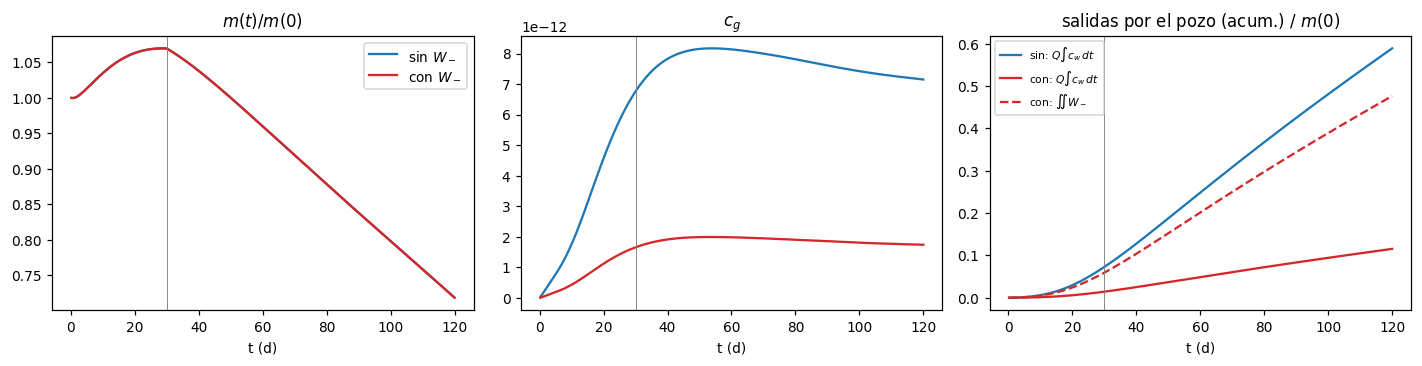

t =  30 d   m/m0 sin/con = 1.06941 / 1.06929   c_g sin/con = 6.760e-12 / 1.658e-12  (×4.1)
t =  60 d   m/m0 sin/con = 0.95991 / 0.95976   c_g sin/con = 8.135e-12 / 1.987e-12  (×4.1)
t = 120 d   m/m0 sin/con = 0.71854 / 0.71840   c_g sin/con = 7.150e-12 / 1.742e-12  (×4.1)

S0/S1 (30 d, BFR y FEniCS; «C captada» = c_g):
BFR (RBF-FD)   con W₋   ∫C final/máx = 1.0000   C captada final = 4.0573e-13   máx = 4.0573e-13
BFR (RBF-FD)   sin W₋   ∫C final/máx = 1.0000   C captada final = 3.2095e-12   máx = 3.2095e-12
FEniCS (FEM)   con W₋   ∫C final/máx = 1.0000   C captada final = 1.6643e-12   máx = 1.6643e-12
FEniCS (FEM)   sin W₋   ∫C final/máx = 1.0000   C captada final = 6.7485e-12   máx = 6.7485e-12



In [10]:
Bf = {"sin": S.cargar_balance_fem("S2_limpieza_sin"), "con": S.cargar_balance_fem("S3_limpieza_con")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, col in (("sin", "tab:blue"), ("con", "tab:red")):
    b = Bf[k]
    ax[0].plot(b["t"], b["masa"], color=col, label=f"{k} $W_-$")
    ax[1].plot(b["t"], b["c_g"], color=col)
    ax[2].plot(b["t"], b["agua"], color=col, label=f"{k}: $Q\\int c_w\\,dt$")
    if k == "con":
        ax[2].plot(b["t"], b["W"], color=col, ls="--", label="con: $\\int\\!\\!\\int W_-$")
ax[0].set(xlabel="t (d)", title="$m(t)/m(0)$"); ax[0].legend()
ax[1].set(xlabel="t (d)", title="$c_g$"); ax[2].set(xlabel="t (d)", title="salidas por el pozo (acum.) / $m(0)$"); ax[2].legend(fontsize=7)
for a in ax: a.axvline(30, color="gray", lw=0.6)
plt.tight_layout(); plt.show()
for d in (30, 60, 120):
    i = [int(np.argmin(np.abs(b["t"] - d))) for b in Bf.values()]
    ms = [b["masa"][j] for b, j in zip(Bf.values(), i)]
    cs = [b["c_g"][j] for b, j in zip(Bf.values(), i)]
    print(f"t = {d:3d} d   m/m0 sin/con = {ms[0]:.5f} / {ms[1]:.5f}   c_g sin/con = {cs[0]:.3e} / {cs[1]:.3e}  (×{cs[0] / cs[1]:.1f})")
res = rutas.grupo("S_sumidero") / "resumen.txt"
print("\nS0/S1 (30 d, BFR y FEniCS; «C captada» = c_g):\n" + res.read_text() if res.exists() else "")

En el dominio real pasa lo mismo. A 120 d, $m(t)$ coincide a 4 cifras con y sin $W_-$ (0.7185 / 0.7184), así que la
limpieza ocurre igual. $c_g$ es 4.1 veces menor con $W_-$, y la celda bien mezclada predice $(Q+\kappa)/Q=(0.3+1)/0.3=4.3$.
A 30 d (S0/S1), $c_g$ es 8 veces menor en BFR y 4 en FEM con $W_-$, e $\int C_m$ coincide a $10^{-4}$.

Sin $W_-$, la salida acumulada $Q\int c_w\,dt$ (≈59 % de $m(0)$) es mucho mayor que la masa perdida (≈36 %). Hay dos
razones: las discretizaciones de la forma no conservativa no conservan masa exactamente (como `fd` en §5), y el
dominio real usa $S_s=\phi$ (§7.1), con el que la masa $\phi\int C_m$ deja de ser la conservada. Ninguna de las
dos tiene que ver con $W_-$.

## 9. Veredicto e implicaciones para la tesis

1. **En la forma no conservativa, la que resuelven los dos backends, el sumidero $W_-$ no hace falta: el pozo ya
   extrae el contaminante a través de $-\mathbf u\cdot\nabla C_m$**, porque la cancelación de §2 es exacta. En todos los
   experimentos, sin $W_-$ la masa sale por el pozo igual que en la forma conservativa de referencia.
2. **Con $W_-$, la masa total que sale casi no cambia**, pero $C_m$ en el entorno del pozo se reduce en un factor
   $Q/(Q+\kappa)$: 2× si $W_-$ llevara $Q$, y entre 4 y 300 veces con la ec. (W_menos). Justo esa cantidad es la que
   pesan $J_m$ y su gradiente.
3. **La ec. (W_menos) es además dimensionalmente incoherente** (m$^{-2}$ en lugar de s$^{-1}$, como ya señala la
   tesis) y, con dispersión, crea un **sumidero fantasma** que limpia el acuífero sin bombear (§7).
4. **Decisión F7–F8:** la evidencia apoya la opción (c), suprimir $W_-$ en la forma no conservativa, o la (b),
   usar la forma conservativa con $-Q\,w_R\,C_m$. Son equivalentes (§2). La opción (a) no se sostiene. Con (c), la
   hipótesis M8 pasa a ser «la extracción de soluto está representada por la advección hacia el pozo» y desaparecen
   $\chi$, $\chi'$ y $\varepsilon_\chi$ del transporte. Conviene anotar que el modelo de pozo-reacción de los peldaños
   del libro sólo vale cuando la velocidad no siente el pozo.
5. **Pendientes que este análisis destapa** (independientes de $W_-$):
   (a) **resuelto el diagnóstico, no la corrección**: la oscilación de $C_m(\mathbf x_p)$ en BFR es un modo local
   inestable del esquema centrado en el pozo, que el recorte $C_m\ge0$ oculta (§8.1.1). Falta decidir el remedio
   (upwind sólo cerca del pozo, hiperviscosidad o forma conservativa) y repetir A–F, que se corrieron con $W_-=1$;
   (b) **corregida la conclusión sobre $S_s\partial_th\,C_m$** (§2, §7.1): con $\theta(t)$ el término no aparece. Lo
   que hay que cambiar es $S_s=\phi$ por un valor físico ($10^{-5}$–$10^{-4}$ m$^{-1}$) en el dominio real;
   (c) las discretizaciones de la forma no conservativa no cierran el balance $Q\int c_w$ con la masa perdida
   (`fd`: 82 % frente a 90 %). Para diagnosticar la masa en el simulador, usar $m(t)$ y no la «salida con el agua».